# 2. Second-Order Runge–Kutta Methods

Euler's method uses a single slope, taken at the start of the step. **Runge–Kutta methods** evaluate $f$ at a few trial points inside the step (called **stages**) and combine the slopes into a better estimate of the average slope. This section covers the methods with two stages: Heun, midpoint and Ralston. All three have order 2.

Test problem: $y' = x + y$, $y(0) = 1$, exact solution $y = 2e^{x} - x - 1$.

## Quick note: RK2 with a calculator

**Use:** solve $y' = f(x, y)$, $y(x_0) = y_0$, one step at a time with step size $h$.

**One step (Heun's method):**

1. Slope at the start: $k_1 = f(x_n,\ y_n)$
2. Slope at the end (using an Euler guess for $y$): $k_2 = f(x_n + h,\ y_n + h\,k_1)$
3. Average the slopes and step: $y_{n+1} = y_n + \dfrac{h}{2}(k_1 + k_2)$
4. Move along: $x_{n+1} = x_n + h$, then repeat.

Each step needs only multiplication, addition and $f$, so a basic calculator is enough.

**Example:** $y' = x + y$, $y(0) = 1$, $h = 0.1$. Find $y(0.2)$.

*Step 1* ($x_0 = 0$, $y_0 = 1$)

- $k_1 = 0 + 1 = 1$
- Euler guess: $1 + 0.1(1) = 1.1$
- $k_2 = 0.1 + 1.1 = 1.2$
- $y_1 = 1 + 0.05(1 + 1.2) = \mathbf{1.11}$

*Step 2* ($x_1 = 0.1$, $y_1 = 1.11$)

- $k_1 = 0.1 + 1.11 = 1.21$
- Euler guess: $1.11 + 0.1(1.21) = 1.231$
- $k_2 = 0.2 + 1.231 = 1.431$
- $y_2 = 1.11 + 0.05(1.21 + 1.431) = \mathbf{1.24205}$

**Check:** the exact answer is $y(0.2) = 2e^{0.2} - 1.2 = 1.242806$, so the error is about $0.0008$. Euler's method with the same $h$ has an error about 10 times larger.

**Tips for working by hand**

- Lay it out as a table: $n$, $x_n$, $y_n$, $k_1$, Euler guess, $k_2$, $y_{n+1}$.
- $h/2$ is just a number (here $0.05$), so work it out once.
- Keep 5 to 6 decimal places in the middle of the working and round only at the end.
- Halving $h$ cuts the error to about $\tfrac14$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
np.set_printoptions(precision=6, suppress=True)

f = lambda x, y: x + y
exact = lambda x: 2 * np.exp(x) - x - 1

def euler(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        y[i + 1] = y[i] + h * f(x[i], y[i])
        x[i + 1] = x[i] + h
    return x, y

## 2.1 Heun's method (improved Euler)

**Derivation from the trapezoidal rule.** Estimate the integral in $y(x_{n+1}) = y(x_n) + \int_{x_n}^{x_{n+1}} f\,dx$ with the trapezoidal rule, which averages the slopes at both ends of the step:

$$y_{n+1} = y_n + \frac{h}{2}\Big[f(x_n, y_n) + f(x_{n+1}, y_{n+1})\Big].$$

The problem is that $y_{n+1}$ appears on both sides (the formula is **implicit**). Heun's fix is to first *predict* $y_{n+1}$ with an Euler step and then *correct* it with the trapezoidal average. That makes it a **predictor–corrector** method:

$$
\begin{aligned}
k_1 &= f(x_n, y_n) && \text{slope at the start}\\
y^{*}_{n+1} &= y_n + h k_1 && \text{predictor (an Euler step)}\\
k_2 &= f(x_{n+1}, y^{*}_{n+1}) && \text{slope at the predicted end point}\\
y_{n+1} &= y_n + \tfrac{h}{2}(k_1 + k_2) && \text{corrector: use the average slope}
\end{aligned}
$$

**Why it is better.** If the curve is concave up, the start slope $k_1$ is too small and the end slope $k_2$ is too large, so their average largely cancels the error. The local error becomes $O(h^3)$ and the global error $O(h^2)$, so Heun is **order 2**. Halving $h$ divides the error by about 4. Each step costs **2** evaluations of $f$.

In [2]:
def heun(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h, y[i] + h * k1)
        y[i + 1] = y[i] + h / 2 * (k1 + k2)
        x[i + 1] = x[i] + h
    return x, y

### Worked example: Heun by hand, $h = 0.1$

| $n$ | $x_n$ | $y_n$ | $k_1 = x_n + y_n$ | $y^{*} = y_n + 0.1k_1$ | $k_2 = x_{n+1} + y^{*}$ | $y_{n+1} = y_n + 0.05(k_1 + k_2)$ | error |
|---|---|---|---|---|---|---|---|
| 0 | 0.0 | 1.000000 | 1.000000 | 1.100000 | 1.200000 | 1.110000 | 0.00034 |
| 1 | 0.1 | 1.110000 | 1.210000 | 1.231000 | 1.431000 | 1.242050 | 0.00076 |
| 2 | 0.2 | 1.242050 | 1.442050 | 1.386255 | 1.686255 | 1.398465 | 0.00125 |

After three steps the error is $0.00125$, about **30 times smaller** than Euler's $0.0377$ (Section 1.2), for twice the work.

## 2.2 The midpoint method

**Derivation from the midpoint rule.** Approximate the integral by $h$ times the slope at the **middle** of the step, $x_n + h/2$. The value of $y$ there is unknown, so estimate it with half an Euler step:

$$
\begin{aligned}
k_1 &= f(x_n, y_n)\\
k_2 &= f\!\left(x_n + \tfrac{h}{2},\ y_n + \tfrac{h}{2}k_1\right) && \text{slope at the estimated midpoint}\\
y_{n+1} &= y_n + h\,k_2
\end{aligned}
$$

Like Heun, it uses two evaluations of $f$ per step and has order 2.

In [3]:
def midpoint(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h / 2, y[i] + h / 2 * k1)
        y[i + 1] = y[i] + h * k2
        x[i + 1] = x[i] + h
    return x, y

## 2.3 A whole family: deriving the conditions for order 2

Heun and midpoint are two members of a one-parameter family. Consider any method of the form

$$
\begin{aligned}
k_1 &= f(x_n, y_n), \qquad k_2 = f(x_n + c\,h,\ y_n + c\,h\,k_1),\\
y_{n+1} &= y_n + h\,(b_1 k_1 + b_2 k_2),
\end{aligned}
$$

and ask: which $b_1, b_2, c$ make the method agree with the Taylor series of the exact solution for as long as possible?

**Taylor series of the exact solution.** Differentiating $y' = f(x, y)$ with the chain rule gives $y'' = f_x + f_y\,y' = f_x + f f_y$, where subscripts denote partial derivatives evaluated at $(x_n, y_n)$. So

$$y(x_n + h) = y + h f + \frac{h^2}{2}\big(f_x + f f_y\big) + O(h^3).$$

**Taylor series of the method.** Expand $k_2$ in two variables:

$$k_2 = f(x + ch,\ y + chf) = f + ch\,f_x + ch f\,f_y + O(h^2),$$

so

$$y_{n+1} = y + h\,(b_1 + b_2)\,f + h^2\,b_2 c\,\big(f_x + f f_y\big) + O(h^3).$$

**Matching** the $h$ and $h^2$ terms for every $f$ requires

$$\boxed{b_1 + b_2 = 1, \qquad b_2\,c = \tfrac{1}{2}}$$

Two equations for three unknowns: one free parameter $c$, with $b_2 = \tfrac{1}{2c}$ and $b_1 = 1 - \tfrac{1}{2c}$.

| $c$ | $b_1$ | $b_2$ | Method |
|---|---|---|---|
| $1$ | $\tfrac12$ | $\tfrac12$ | Heun |
| $\tfrac12$ | $0$ | $1$ | midpoint |
| $\tfrac23$ | $\tfrac14$ | $\tfrac34$ | Ralston |

**Why two stages cannot reach order 3.** The $h^3$ term of the exact solution contains $y^{\prime\prime\prime} = f_{xx} + 2ff_{xy} + f^2 f_{yy} + f_y(f_x + ff_y)$. The method's $h^3$ term comes only from the second-order part of the expansion of $k_2$, which contains $f_{xx}, f_{xy}, f_{yy}$ but **never** the product $f_y(f_x + f f_y)$. No choice of $b_1, b_2, c$ can match it, so order 3 needs at least three stages.

**Ralston's choice** $c = \tfrac23$ minimises a bound on the $h^3$ error term over all $f$, so it is often slightly more accurate than Heun or midpoint.

The code implements the whole family with $c$ as a parameter.

In [4]:
def rk2(f, x0, y0, h, n, c):
    b2 = 1 / (2 * c)
    b1 = 1 - b2
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + c * h, y[i] + c * h * k1)
        y[i + 1] = y[i] + h * (b1 * k1 + b2 * k2)
        x[i + 1] = x[i] + h
    return x, y

ralston = lambda f, x0, y0, h, n: rk2(f, x0, y0, h, n, 2 / 3)

# rk2 with c = 1 and c = 1/2 must reproduce Heun and midpoint exactly
print(np.max(np.abs(rk2(f, 0, 1, 0.1, 10, 1.0)[1] - heun(f, 0, 1, 0.1, 10)[1])))
print(np.max(np.abs(rk2(f, 0, 1, 0.1, 10, 0.5)[1] - midpoint(f, 0, 1, 0.1, 10)[1])))

0.0
0.0


## 2.4 Comparing the family

**A caution about the test problem.** For $f = x + y$ every member of the family gives the *same* numbers. With $k_1 = x_n + y_n$,

$$k_2 = (x_n + ch) + (y_n + chk_1) = k_1 + ch(1 + k_1), \qquad y_{n+1} = y_n + hk_1 + \underbrace{b_2c}_{=1/2}\,h^2(1 + k_1),$$

which does not depend on $c$. Because $f$ is linear, the second derivatives $f_{xx}, f_{xy}, f_{yy}$ vanish and the only place the methods could differ disappears. To compare them we need an $f$ that is **nonlinear** in $x$ or $y$:

$$y' = y - x^2 + 1, \qquad y(0) = 0.5, \qquad \text{exact solution } y = (x + 1)^2 - \tfrac12 e^{x}.$$

In [5]:
p = lambda x, y: y - x**2 + 1
p_exact = lambda x: (x + 1)**2 - 0.5 * np.exp(x)

methods = {"Euler": euler, "Heun": heun, "Midpoint": midpoint, "Ralston": ralston}
hs = [0.2, 0.1, 0.05, 0.025]
print(f"error at x = 2 for y' = y − x² + 1\n{'h':>7}" + "".join(f"{m:>12}{'ratio':>7}" for m in methods))
errs = {m: [] for m in methods}
for i, h in enumerate(hs):
    row = f"{h:7.3f}"
    for m, method in methods.items():
        _, y = method(p, 0, 0.5, h, round(2 / h))
        errs[m].append(abs(p_exact(2) - y[-1]))
        ratio = f"{errs[m][-2] / errs[m][-1]:7.2f}" if i else " " * 7
        row += f"{errs[m][-1]:12.3e}{ratio}"
    print(row)

error at x = 2 for y' = y − x² + 1
      h       Euler  ratio        Heun  ratio    Midpoint  ratio     Ralston  ratio
  0.200   4.397e-01          7.242e-02          1.510e-02          3.421e-02       
  0.100   2.420e-01   1.82   1.890e-02   3.83   3.747e-03   4.03   8.800e-03   3.89
  0.050   1.275e-01   1.90   4.820e-03   3.92   9.277e-04   4.04   2.225e-03   3.95
  0.025   6.550e-02   1.95   1.216e-03   3.96   2.304e-04   4.03   5.590e-04   3.98


The ratios approach $2$ for Euler and $4$ for the three second-order methods. On this problem the midpoint method has the smallest error and Heun the largest, with Ralston in between. Ralston's choice minimises a bound over *all* $f$, which does not make it the best for every particular $f$. All three are far ahead of Euler.

## 2.5 Seeing the slopes

One large step ($h = 0.5$) on the test problem shows where each method samples the slope. Heun samples at the **end** of the step, midpoint in the **middle**. Short thick lines mark each sampled slope; the dashed line is the step actually taken.

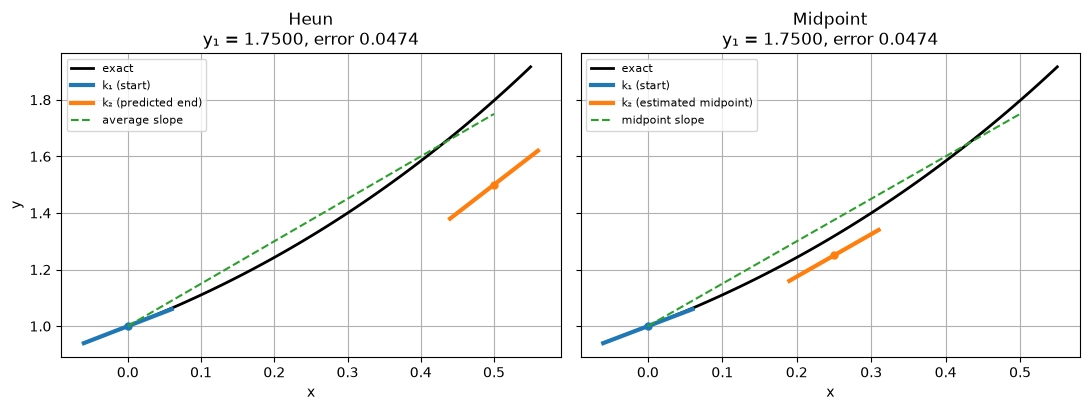

In [6]:
def slope_mark(ax, x, y, s, color, label=None):
    d = 0.06
    ax.plot([x - d, x + d], [y - d * s, y + d * s], color=color, lw=3, label=label)
    ax.plot(x, y, "o", color=color, ms=5)

h, x0, y0 = 0.5, 0.0, 1.0
xf = np.linspace(0, 0.55, 100)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax in axes:
    ax.plot(xf, exact(xf), "k", lw=2, label="exact")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")

k1 = f(x0, y0)
k2 = f(x0 + h, y0 + h * k1)
y_h = y0 + h / 2 * (k1 + k2)
slope_mark(axes[0], x0, y0, k1, "C0", "k₁ (start)")
slope_mark(axes[0], x0 + h, y0 + h * k1, k2, "C1", "k₂ (predicted end)")
axes[0].plot([x0, h], [y0, y_h], "C2--", label="average slope")
axes[0].set_title(f"Heun\ny₁ = {y_h:.4f}, error {exact(h) - y_h:.4f}")

m2 = f(x0 + h / 2, y0 + h / 2 * k1)
y_m = y0 + h * m2
slope_mark(axes[1], x0, y0, k1, "C0", "k₁ (start)")
slope_mark(axes[1], x0 + h / 2, y0 + h / 2 * k1, m2, "C1", "k₂ (estimated midpoint)")
axes[1].plot([x0, h], [y0, y_m], "C2--", label="midpoint slope")
axes[1].set_title(f"Midpoint\ny₁ = {y_m:.4f}, error {exact(h) - y_m:.4f}")
for ax in axes:
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()

The two methods sample different slopes but land on the same value, as Section 2.4 predicted for this linear test problem.

## 2.6 Example: a problem where Euler misbehaves

$$y' = -2xy, \qquad y(0) = 1, \qquad \text{exact solution } y = e^{-x^2}, \qquad h = 0.25.$$

Euler's update is $y_{n+1} = (1 - 2x_n h)\,y_n$. At $x_n = 2$ the factor is exactly $0$, and for $x_n > 2$ it is **negative**, so Euler's solution hits zero and then changes sign at every step. The true solution is positive and decays smoothly. (Section 5 explains this as an instability: the step is too large for how quickly the solution decays.)

Euler    max |error| = 0.0962
Heun     max |error| = 0.0161
Midpoint max |error| = 0.0084


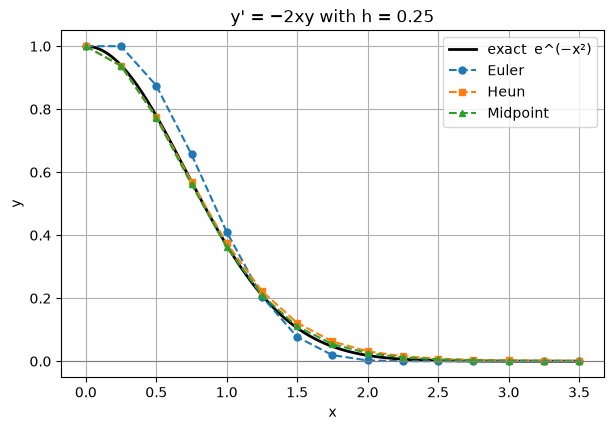

In [7]:
g = lambda x, y: -2 * x * y
g_exact = lambda x: np.exp(-x**2)
h, n = 0.25, 14
xf = np.linspace(0, 3.5, 300)
plt.plot(xf, g_exact(xf), "k", lw=2, label="exact  e^(−x²)")
for name, method, style in [("Euler", euler, "o--"), ("Heun", heun, "s--"), ("Midpoint", midpoint, "^--")]:
    x, y = method(g, 0, 1, h, n)
    plt.plot(x, y, style, ms=5, label=name)
    print(f"{name:8s} max |error| = {np.max(np.abs(y - g_exact(x))):.4f}")
plt.axhline(0, color="gray", lw=0.8)
plt.xlabel("x"); plt.ylabel("y"); plt.title("y' = −2xy with h = 0.25"); plt.legend();

## 2.7 Summary

| Method | Stages ($f$ evaluations per step) | Order | Idea |
|---|---|---|---|
| Euler | 1 | 1 | slope at the start |
| Heun | 2 | 2 | average of start slope and predicted end slope |
| Midpoint | 2 | 2 | slope at an estimated midpoint |
| Ralston | 2 | 2 | the member of the family with the smallest error bound |

* Every two-stage method with $b_1 + b_2 = 1$ and $b_2c = \tfrac12$ has order 2. Two stages can never give order 3.
* On a linear test problem all of them agree. Use a nonlinear problem to tell them apart.

## Exercises

1. For $y' = y - x^2 + 1$, $y(0) = 0.5$, take one step with $h = 0.2$ using Heun, midpoint and Ralston by hand. Compare with $y(0.2) = 1.44 - 0.5e^{0.2}$.
2. Show that for $y' = x + y$, $y(0) = 1$, the first step of any member of the family gives $y_1 = 1 + h + h^2$. How does this compare with the Taylor series $y(h) = 1 + h + h^2 + h^3/3 + \cdots$?
3. Apply a two-stage method to $y' = 1$. Show that it gives the exact answer only if $b_1 + b_2 = 1$. (This is why that condition is called **consistency**.)
4. Write down the member of the family with $c = \tfrac34$ and measure its order numerically.

**Answers**

1. Heun: $k_1 = 1.5$, $y^{*} = 0.8$, $k_2 = 1.76$, $y_1 = 0.826$. Midpoint: $k_2 = f(0.1, 0.65) = 1.64$, $y_1 = 0.828$. Ralston: $k_2 = f(0.1\overline{3}, 0.7) = 1.682\overline{2}$, $y_1 = 0.827\overline{3}$. Exact: $0.829299$.
2. $k_1 = 1$, $k_2 = 1 + ch(1 + 1) = 1 + 2ch$, so $y_1 = 1 + h(b_1 + b_2) + 2b_2c\,h^2 = 1 + h + h^2$. It matches the Taylor series up to $h^2$ and misses $h^3/3$: that is the local error.
3. $k_1 = k_2 = 1$, so $y_{n+1} = y_n + (b_1 + b_2)h$, while the exact solution increases by $h$.
4. $b_2 = \tfrac23$, $b_1 = \tfrac13$. See the cell below: the error ratio approaches 4.

In [8]:
for name, method in [("Heun", heun), ("Midpoint", midpoint), ("Ralston", ralston)]:
    _, y = method(p, 0, 0.5, 0.2, 1)
    print(f"1.  {name:8s} y(0.2) ≈ {y[1]:.6f}   (exact {p_exact(0.2):.6f})")

prev = None
for h in [0.2, 0.1, 0.05, 0.025]:
    _, y = rk2(p, 0, 0.5, h, round(2 / h), c=3 / 4)
    err = abs(p_exact(2) - y[-1])
    print(f"4.  c = 3/4, h = {h:5}: error {err:.3e}" + (f",  ratio {prev / err:.2f}" if prev else ""))
    prev = err

1.  Heun     y(0.2) ≈ 0.826000   (exact 0.829299)
1.  Midpoint y(0.2) ≈ 0.828000   (exact 0.829299)
1.  Ralston  y(0.2) ≈ 0.827333   (exact 0.829299)
4.  c = 3/4, h =   0.2: error 4.376e-02
4.  c = 3/4, h =   0.1: error 1.133e-02,  ratio 3.86
4.  c = 3/4, h =  0.05: error 2.874e-03,  ratio 3.94
4.  c = 3/4, h = 0.025: error 7.233e-04,  ratio 3.97
